In [1]:
!pip install requests beautifulsoup4 pandas matplotlib seaborn

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
url = "https://books.toscrape.com/"

response = requests.get(url, timeout=30)

print("Status Code:", response.status_code)
print("Website Connected:", response.status_code == 200)

Status Code: 200
Website Connected: True


In [4]:
# Display first 1000 characters of HTML
print(response.text[:1000])

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html lang="en-us" class="no-js"> <!--<![endif]-->
    <head>
        <title>
    All products | Books to Scrape - Sandbox
</title>

        <meta http-equiv="content-type" content="text/html; charset=UTF-8" />
        <meta name="created" content="24th Jun 2016 09:29" />
        <meta name="description" content="" />
        <meta name="viewport" content="width=device-width" />
        <meta name="robots" content="NOARCHIVE,NOCACHE" />

        <!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
        <!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif]-->

        
            <link rel="shortcut icon" href="static/oscar/favicon.

In [5]:
from bs4 import BeautifulSoup

# Parse HTML content
soup = BeautifulSoup(response.text, "html.parser")

print("HTML Parsing Successful!")

HTML Parsing Successful!


In [6]:
title = soup.title.text.strip()

print("Website Title:", title)

Website Title: All products | Books to Scrape - Sandbox


In [7]:
products = soup.find_all("article", class_="product_pod")

print("Total Products Found:", len(products))

Total Products Found: 20


In [8]:
# Inspect the first product HTML
print(products[0].prettify())

<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [9]:
# Select the first product
first_product = products[0]

# Extract Product Information
name = first_product.h3.a["title"]

price = first_product.find(
    "p", class_="price_color"
).text.strip()

rating = first_product.find(
    "p", class_="star-rating"
)["class"][1]

availability = first_product.find(
    "p", class_="instock availability"
).text.strip()

# Display Information
print("Product Name:", name)
print("Product Price:", price)
print("Product Rating:", rating)
print("Availability:", availability)

Product Name: A Light in the Attic
Product Price: Â£51.77
Product Rating: Three
Availability: In stock


In [10]:
# Create an empty list to store product data
product_data = []

In [11]:
for product in products:

    name = product.h3.a["title"]

    price = product.find(
        "p", class_="price_color"
    ).text.strip()

    rating = product.find(
        "p", class_="star-rating"
    )["class"][1]

    availability = product.find(
        "p", class_="instock availability"
    ).text.strip()

    product_data.append({
        "Product Name": name,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

print("Total Scraped Products:", len(product_data))

Total Scraped Products: 20


In [12]:
df = pd.DataFrame(product_data)

df.head()

,Product Name,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [13]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (20, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Product Name  20 non-null     object
 1   Price         20 non-null     object
 2   Rating        20 non-null     object
 3   Availability  20 non-null     object
dtypes: object(4)
memory usage: 772.0+ bytes

Missing Values:
Product Name    0
Price           0
Rating          0
Availability    0
dtype: int64


In [14]:
# Fix currency encoding
df["Price"] = df["Price"].str.replace("Â£", "", regex=False)

# Convert Price to Numeric
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

# Display Result
print(df[["Product Name", "Price"]].head())

                            Product Name  Price
0                   A Light in the Attic  51.77
1                     Tipping the Velvet  53.74
2                             Soumission  50.10
3                          Sharp Objects  47.82
4  Sapiens: A Brief History of Humankind  54.23


In [15]:
# Map Rating Text into Numbers

rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_mapping)

print(df[["Product Name", "Rating"]].head())

                            Product Name  Rating
0                   A Light in the Attic       3
1                     Tipping the Velvet       1
2                             Soumission       1
3                          Sharp Objects       4
4  Sapiens: A Brief History of Humankind       5


In [16]:
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product Name  20 non-null     object 
 1   Price         20 non-null     float64
 2   Rating        20 non-null     int64  
 3   Availability  20 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 772.0+ bytes
None

Missing Values:
Product Name    0
Price           0
Rating          0
Availability    0
dtype: int64


In [17]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
import time

base_url = "https://books.toscrape.com/catalogue/page-{}.html"

all_products = []

for page in range(1, 51):

    url = base_url.format(page)

    response = requests.get(url, timeout=30)

    if response.status_code == 200:

        soup = BeautifulSoup(response.text, "html.parser")

        products = soup.find_all(
            "article", class_="product_pod"
        )

        for product in products:

            name = product.h3.a["title"]

            price = product.find(
                "p", class_="price_color"
            ).text.strip()

            rating = product.find(
                "p", class_="star-rating"
            )["class"][1]

            availability = product.find(
                "p", class_="instock availability"
            ).text.strip()

            all_products.append({
                "Product Name": name,
                "Price": price,
                "Rating": rating,
                "Availability": availability
            })

        print(f"Page {page}: {len(products)} products scraped")

    else:
        print(f"Page {page}: Failed - {response.status_code}")

    time.sleep(0.5)

print("\nTotal Products Scraped:", len(all_products))

Page 1: 20 products scraped
Page 2: 20 products scraped
Page 3: 20 products scraped
Page 4: 20 products scraped
Page 5: 20 products scraped
Page 6: 20 products scraped
Page 7: 20 products scraped
Page 8: 20 products scraped
Page 9: 20 products scraped
Page 10: 20 products scraped
Page 11: 20 products scraped
Page 12: 20 products scraped
Page 13: 20 products scraped
Page 14: 20 products scraped
Page 15: 20 products scraped
Page 16: 20 products scraped
Page 17: 20 products scraped
Page 18: 20 products scraped
Page 19: 20 products scraped
Page 20: 20 products scraped
Page 21: 20 products scraped
Page 22: 20 products scraped
Page 23: 20 products scraped
Page 24: 20 products scraped
Page 25: 20 products scraped
Page 26: 20 products scraped
Page 27: 20 products scraped
Page 28: 20 products scraped
Page 29: 20 products scraped
Page 30: 20 products scraped
Page 31: 20 products scraped
Page 32: 20 products scraped
Page 33: 20 products scraped
Page 34: 20 products scraped
Page 35: 20 products sc

In [18]:
# Convert scraped data into DataFrame

df = pd.DataFrame(all_products)

# Display first 10 rows
df.head(10)

,Product Name,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock
5,The Requiem Red,Â£22.65,One,In stock
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,Four,In stock
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,Three,In stock
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,Four,In stock
9,The Black Maria,Â£52.15,One,In stock


In [19]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (1000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Product Name  1000 non-null   object
 1   Price         1000 non-null   object
 2   Rating        1000 non-null   object
 3   Availability  1000 non-null   object
dtypes: object(4)
memory usage: 31.4+ KB

Missing Values:
Product Name    0
Price           0
Rating          0
Availability    0
dtype: int64


In [20]:
# Clean Price
df["Price"] = (
    df["Price"]
    .str.replace("Â£", "", regex=False)
    .str.replace("£", "", regex=False)
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

# Convert Rating into Numeric
rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_mapping)

# Check result
df.head()

,Product Name,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


In [21]:
# Export CSV
df.to_csv("books_dataset.csv", index=False)

# Export Excel
df.to_excel("books_dataset.xlsx", index=False)

print("CSV and Excel files created successfully!")

CSV and Excel files created successfully!


In [22]:
from google.colab import files

files.download("books_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
files.download("books_dataset.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Columns:")
print(df.columns.tolist())

Dataset Shape: (1000, 4)


,Product Name,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock



Dataset Columns:
['Product Name', 'Price', 'Rating', 'Availability']


In [25]:
# Checking for Missing Values, Duplicates, and Data Types


# Missing Values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate Rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Data Types
print("\nData Types:")
print(df.dtypes)

Missing Values:
Product Name    0
Price           0
Rating          0
Availability    0
dtype: int64

Duplicate Rows:
0

Data Types:
Product Name     object
Price           float64
Rating            int64
Availability     object
dtype: object


In [26]:
display(df.head())

print(df.dtypes)

,Product Name,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


Product Name     object
Price           float64
Rating            int64
Availability     object
dtype: object


In [27]:
print("Duplicate Product Names:",
      df["Product Name"].duplicated().sum())

print("\nRating Values:")
print(sorted(df["Rating"].unique()))

print("\nAvailability Values:")
print(df["Availability"].value_counts())

print("\nPrice Summary:")
display(df["Price"].describe())

Duplicate Product Names: 1

Rating Values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Availability Values:
Availability
In stock    1000
Name: count, dtype: int64

Price Summary:


,Price
count,1000.00000
mean,35.07035
std,14.44669
min,10.00000
25%,22.10750
50%,35.98000
75%,47.45750
max,59.99000


In [28]:
duplicate_books = df[
    df["Product Name"].duplicated(keep=False)
]

display(duplicate_books)

,Product Name,Price,Rating,Availability
236,The Star-Touched Queen,46.02,5,In stock
358,The Star-Touched Queen,32.30,5,In stock


In [29]:
print("Duplicate Product Count:",
      df["Product Name"].duplicated().sum())

print("\nDuplicate Product Details:")

display(
    duplicate_books[
        ["Product Name", "Price", "Rating", "Availability"]
    ]
)

Duplicate Product Count: 1

Duplicate Product Details:


,Product Name,Price,Rating,Availability
236,The Star-Touched Queen,46.02,5,In stock
358,The Star-Touched Queen,32.30,5,In stock


In [30]:
# Feature Engineering – Rating Category

def categorize_rating(rating):
    if rating <= 2:
        return "Low"
    elif rating == 3:
        return "Medium"
    else:
        return "High"

df["Rating_Category"] = df["Rating"].apply(
    categorize_rating
)

display(df[["Rating", "Rating_Category"]].head(10))

,Rating,Rating_Category
0,3,Medium
1,1,Low
2,1,Low
3,4,High
4,5,High
5,1,Low
6,4,High
7,3,Medium
8,4,High
9,1,Low


In [31]:
# Feature Engineering – Price Category

df["Price_Category"] = pd.qcut(
    df["Price"],
    q=3,
    labels=["Low", "Medium", "High"]
)

display(df[["Price", "Price_Category"]].head(10))

,Price,Price_Category
0,51.77,High
1,53.74,High
2,50.10,High
3,47.82,High
4,54.23,High
5,22.65,Low
6,33.34,Medium
7,17.93,Low
8,22.60,Low
9,52.15,High


In [32]:
print("Rating Category:")
print(df["Rating_Category"].value_counts())

print("\nPrice Category:")
print(df["Price_Category"].value_counts())

print("\nFinal Dataset Shape:", df.shape)

display(df.head(10))

Rating Category:
Rating_Category
Low       422
High      375
Medium    203
Name: count, dtype: int64

Price Category:
Price_Category
Low       334
Medium    333
High      333
Name: count, dtype: int64

Final Dataset Shape: (1000, 6)


,Product Name,Price,Rating,Availability,Rating_Category,Price_Category
0,A Light in the Attic,51.77,3,In stock,Medium,High
1,Tipping the Velvet,53.74,1,In stock,Low,High
2,Soumission,50.10,1,In stock,Low,High
3,Sharp Objects,47.82,4,In stock,High,High
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,High,High
5,The Requiem Red,22.65,1,In stock,Low,Low
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,High,Medium
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,Medium,Low
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,High,Low
9,The Black Maria,52.15,1,In stock,Low,High


In [33]:
# Rating Distribution Analysis

rating_counts = df["Rating"].value_counts().sort_index()

print(rating_counts)

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


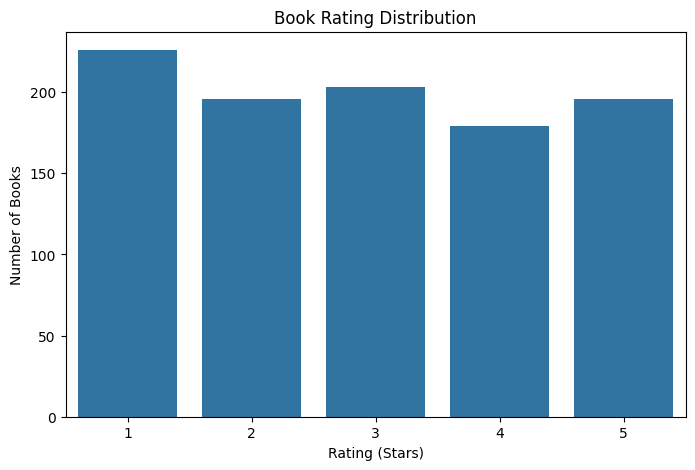

In [34]:
# Rating Distribution Visualization
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Rating")

plt.title("Book Rating Distribution")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Books")

plt.show()

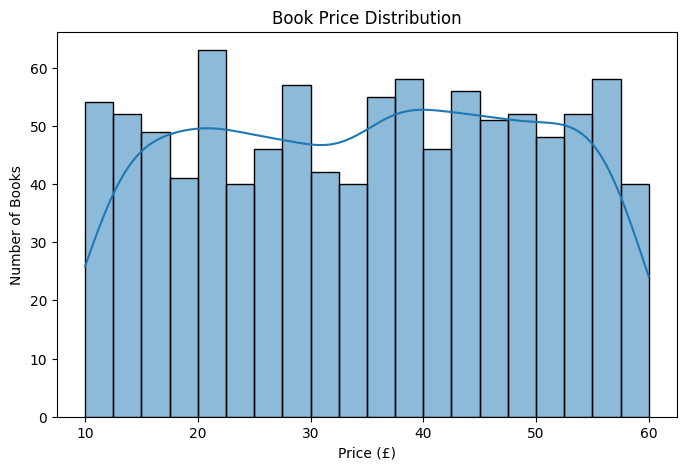

In [35]:
 # Price Distribution Visualization

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Price", bins=20, kde=True)

plt.title("Book Price Distribution")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()

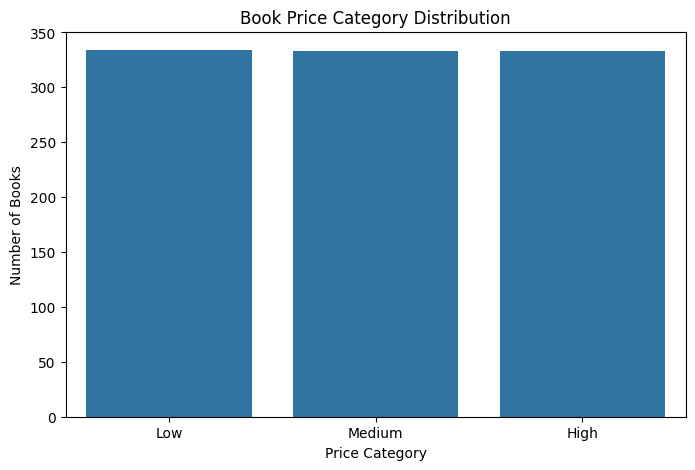

In [36]:
# Price Category Distribution Chart

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Price_Category",
    order=["Low", "Medium", "High"]
)

plt.title("Book Price Category Distribution")
plt.xlabel("Price Category")
plt.ylabel("Number of Books")

plt.show()

In [37]:
print("Average Price:", round(df["Price"].mean(), 2))
print("Median Price:", round(df["Price"].median(), 2))
print("Minimum Price:", df["Price"].min())
print("Maximum Price:", df["Price"].max())

Average Price: 35.07
Median Price: 35.98
Minimum Price: 10.0
Maximum Price: 59.99


In [38]:
# Average Price based on Rating

average_price = df.groupby("Rating")["Price"].mean()

print("Average Price by Rating:")
print(average_price.round(2))

Average Price by Rating:
Rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: Price, dtype: float64


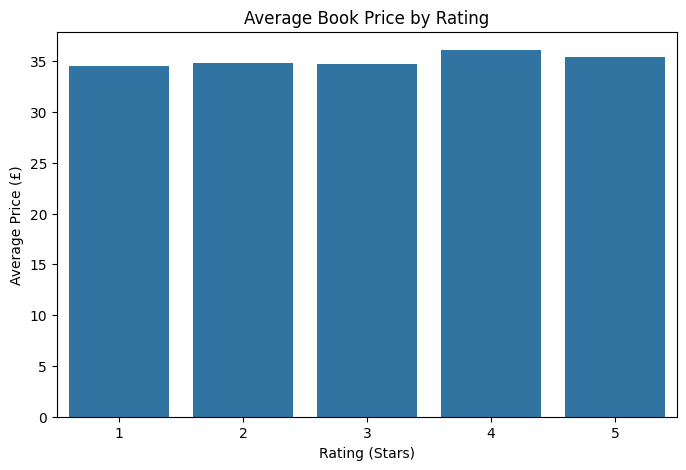

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Rating",
    y="Price",
    errorbar=None
)

plt.title("Average Book Price by Rating")
plt.xlabel("Rating (Stars)")
plt.ylabel("Average Price (£)")

plt.show()

In [40]:
print("Price Category Distribution:")

print(
    df["Price_Category"]
    .value_counts()
    .sort_index()
)

Price Category Distribution:
Price_Category
Low       334
Medium    333
High      333
Name: count, dtype: int64


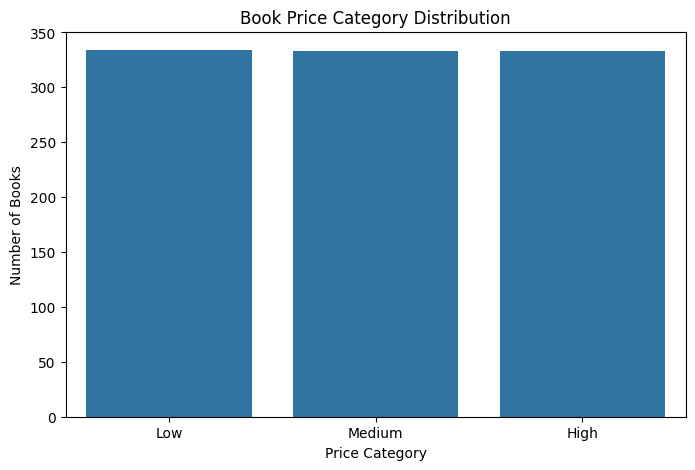

In [41]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Price_Category",
    order=["Low", "Medium", "High"]
)

plt.title("Book Price Category Distribution")
plt.xlabel("Price Category")
plt.ylabel("Number of Books")

plt.show()

In [42]:
eda_summary = {
    "Total Books": len(df),
    "Average Price": round(df["Price"].mean(), 2),
    "Median Price": round(df["Price"].median(), 2),
    "Minimum Price": df["Price"].min(),
    "Maximum Price": df["Price"].max(),
    "Average Rating": round(df["Rating"].mean(), 2),
    "Missing Values": df.isnull().sum().sum(),
    "Duplicate Rows": df.duplicated().sum()
}

summary_df = pd.DataFrame(
    list(eda_summary.items()),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Total Books,1000.00
1,Average Price,35.07
2,Median Price,35.98
3,Minimum Price,10.00
4,Maximum Price,59.99
5,Average Rating,2.92
6,Missing Values,0.00
7,Duplicate Rows,0.00


In [43]:
print("Dataset Shape:", df.shape)

print("\nAll Columns:")
print(df.columns.tolist())

print("\nRating Category:")
print(df["Rating_Category"].value_counts())

print("\nPrice Category:")
print(df["Price_Category"].value_counts())

Dataset Shape: (1000, 6)

All Columns:
['Product Name', 'Price', 'Rating', 'Availability', 'Rating_Category', 'Price_Category']

Rating Category:
Rating_Category
Low       422
High      375
Medium    203
Name: count, dtype: int64

Price Category:
Price_Category
Low       334
Medium    333
High      333
Name: count, dtype: int64


In [44]:
# Export CSV
df.to_csv("books_dataset.csv", index=False)

# Export Excel
df.to_excel("books_dataset.xlsx", index=False)

print("CSV and Excel files created successfully!")

CSV and Excel files created successfully!


In [45]:
files.download("books_dataset.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>